In [3]:
# Make the project importable and use the project root as working folder
import os, sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: e:\AI ENGINEER INTERVIEW PREPARATION\Smart-Surveillance-AI_Project


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from collections import Counter

from src.config import *

plt.rcParams["figure.dpi"] = 100

(2252, 4)


,path,label,split,source_image
0,images/train/without_mask/maksssksksss540_0.jpg,without_mask,train,maksssksksss540
1,images/train/with_mask/maksssksksss481_0.jpg,with_mask,train,maksssksksss481
2,images/train/with_mask/maksssksksss481_1.jpg,with_mask,train,maksssksksss481
3,images/train/with_mask/maksssksksss481_3.jpg,with_mask,train,maksssksksss481
4,images/train/with_mask/maksssksksss441_0.jpg,with_mask,train,maksssksksss441


label,mask_weared_incorrect,with_mask,without_mask
split,,,
test,13,285,40
train,56,1288,220
val,12,281,57


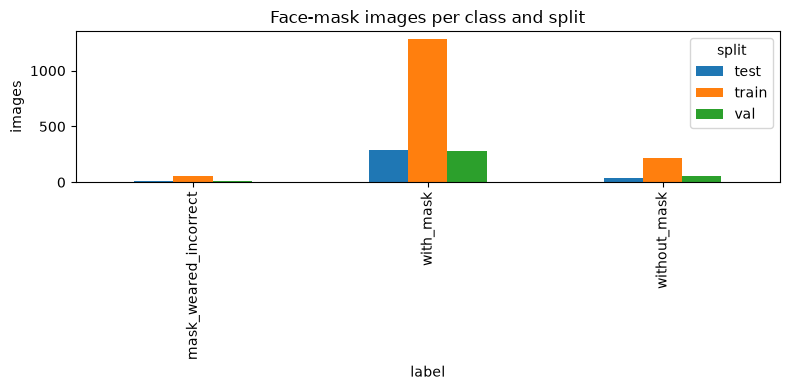

Imbalance ratio (largest / smallest class in train): 23.0


In [5]:
mask_df = pd.read_csv(MASK_LABELS_CSV)
print(mask_df.shape)
display(mask_df.head())

table = pd.crosstab(mask_df["split"], mask_df["label"])
display(table)

ax = table.T.plot(kind="bar", figsize=(8, 4), title="Face-mask images per class and split")
ax.set_ylabel("images")
plt.tight_layout()
plt.show()

train_counts = table.loc["train"]
print("Imbalance ratio (largest / smallest class in train):",
      round(train_counts.max() / train_counts.min(), 1))

In [6]:
# Image sizes (the crops are small, so they get upscaled to 224x224 for the models)
sizes = []
for p in mask_df["path"].sample(300, random_state=SEED):
    img = cv2.imread(str(MASK_DIR / p))
    sizes.append(img.shape[:2])
sizes = pd.DataFrame(sizes, columns=["height", "width"])
display(sizes.describe().loc[["min", "mean", "max"]].round(1))

,height,width
min,26.0,23.0
mean,63.5,56.4
max,247.0,249.0


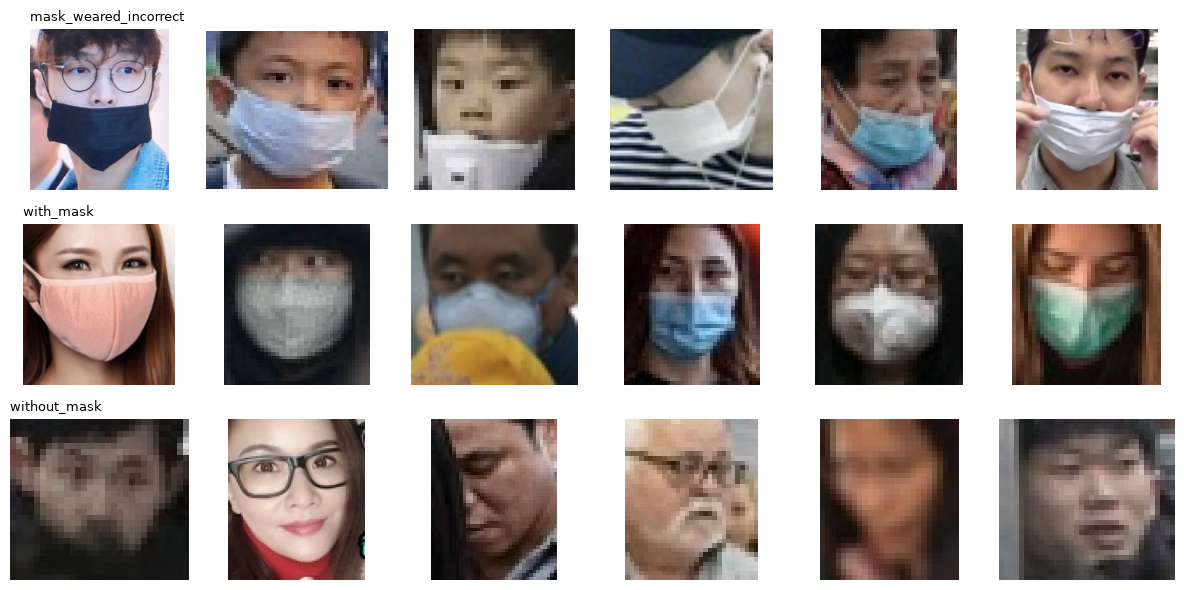

In [7]:
fig, axes = plt.subplots(len(MASK_CLASSES), 6, figsize=(12, 6))
for r, cls in enumerate(MASK_CLASSES):
    paths = mask_df[(mask_df["label"] == cls) & (mask_df["split"] == "train")]["path"].sample(6, random_state=SEED)
    for c, p in enumerate(paths):
        img = cv2.cvtColor(cv2.imread(str(MASK_DIR / p)), cv2.COLOR_BGR2RGB)
        axes[r, c].imshow(img)
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(cls, loc="left", fontsize=9)
plt.tight_layout()
plt.show()

,video_path,label,split,source_group,n_frames_saved
0,videos/Walking/Finding_Forrester_1_walk_f_nm_n...,Walking,train,Finding_Forrester_1_walk,16
1,videos/Walking/TheLastManOnearth_walk_f_cm_np1...,Walking,train,TheLastManOnearth_walk,16
2,videos/Sitting/AmericanGangster_sit_u_cm_np1_b...,Sitting,train,AmericanGangster_sit,16
3,videos/Standing/Shadow_of_a_Doubt_stand_u_cm_n...,Standing,train,Shadow_of_a_Doubt_stand,16


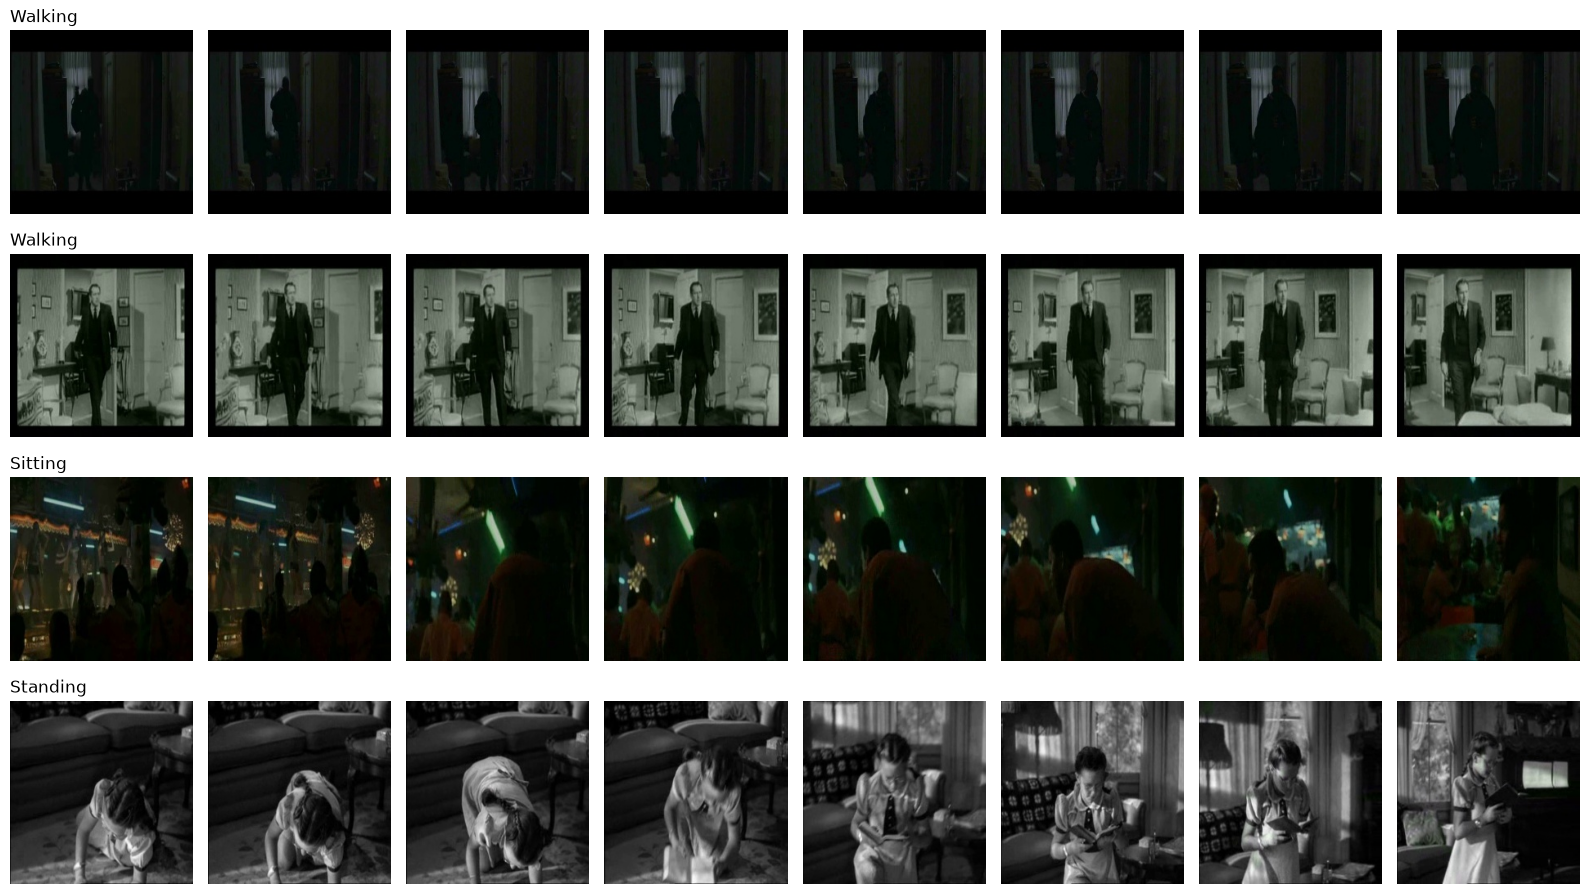

In [8]:
from src.activity_detection import find_frames_folder, read_frames_folder

act_df = pd.read_csv(ACTIVITY_LABELS_CSV)
display(act_df)

fig, axes = plt.subplots(len(act_df), 8, figsize=(16, 2.3 * len(act_df)))
for r, row in act_df.iterrows():
    frames = read_frames_folder(find_frames_folder(ACTIVITY_DIR / row["video_path"]))
    idx = np.linspace(0, len(frames) - 1, 8).astype(int)
    for c, i in enumerate(idx):
        axes[r, c].imshow(cv2.cvtColor(frames[i], cv2.COLOR_BGR2RGB))
        axes[r, c].axis("off")
    axes[r, 0].set_title(row["label"], loc="left")
plt.tight_layout()
plt.show()

(1536, 2) | duplicates: 0


,text,label
1159,a woman slipped and fell in the corridor.,Fall Report
76,A woman walked calmly on the staircase while c...,Normal Activity
316,An elderly man stood in line at the main gate ...,Normal Activity
1040,An elderly man bolted at the loading dock with...,Rapid Movement
1357,A young woman lost balance while carrying a ba...,Fall Report
924,An elderly man was waiting beside the elevator...,Normal Activity
757,"An elderly man fell down in the lobby, other p...",Fall Report
1505,Facility alert: fire exit sign at the main gat...,Facility Issue


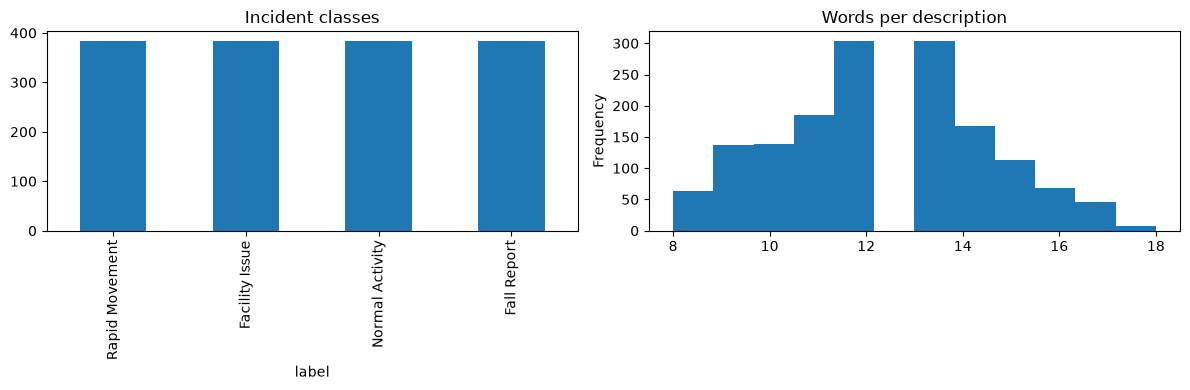

Facility Issue   ['water', 'floor', 'door', 'exit', 'corridor', 'elevator', 'gate', 'jammed']
Fall Report      ['while', 'fell', 'ground', 'down', 'floor', 'lying', 'man', 'woman']
Normal Activity  ['walked', 'while', 'building', 'waiting', 'line', 'entered', 'showed', 'access']
Rapid Movement   ['while', 'running', 'exit', 'man', 'woman', 'hurried', 'high', 'speed']


In [9]:
txt = pd.read_csv(INCIDENT_CSV)
print(txt.shape, "| duplicates:", txt.duplicated().sum())
display(txt.sample(8, random_state=SEED))

txt["n_words"] = txt["text"].str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
txt["label"].value_counts().plot(kind="bar", ax=axes[0], title="Incident classes")
txt["n_words"].plot(kind="hist", bins=12, ax=axes[1], title="Words per description")
plt.tight_layout()
plt.show()

STOP = set("a an the of in on at to and it is was by with near for from this that his her their there".split())
for label, g in txt.groupby("label"):
    words = Counter(w for t in g["text"]
                    for w in t.lower().replace(",", " ").replace(".", " ").split() if w not in STOP)
    print(f"{label:16s}", [w for w, _ in words.most_common(8)])

In [10]:
safe = pd.read_csv(SAFETY_CSV)
print(safe.shape, "| missing values:", int(safe.isna().sum().sum()))
display(safe.describe().T.round(2))
display(safe.groupby(SAFETY_TARGET)[SAFETY_FEATURES].mean().round(1))
print(safe[SAFETY_TARGET].value_counts())

(2382, 6) | missing values: 0


,count,mean,std,min,25%,50%,75%,max
duration_seconds,2382.0,316.66,352.92,5.0,95.0,154.0,333.5,1679.0
people_count,2382.0,7.40,5.14,1.0,4.0,6.0,9.0,34.0
mask_issue_count,2382.0,2.05,2.18,0.0,0.0,1.0,3.0,12.0
motion_change_count,2382.0,7.50,6.13,0.0,3.0,5.0,10.0,32.0


,duration_seconds,people_count,mask_issue_count,motion_change_count
event_category,,,,
long_group_event_demo,863.8,13.9,1.7,6.8
mask_observation_demo,154.5,6.1,4.9,4.2
movement_observation_demo,112.7,5.3,1.0,15.7
normal_demo,123.9,4.1,0.6,3.1


event_category
movement_observation_demo    606
long_group_event_demo        605
mask_observation_demo        599
normal_demo                  572
Name: count, dtype: int64


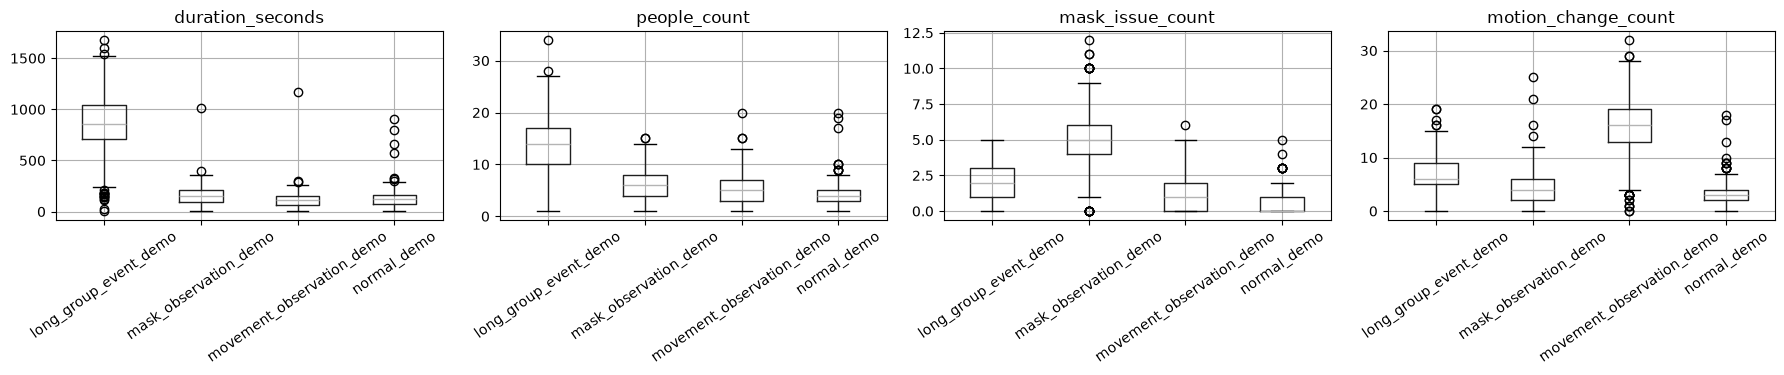

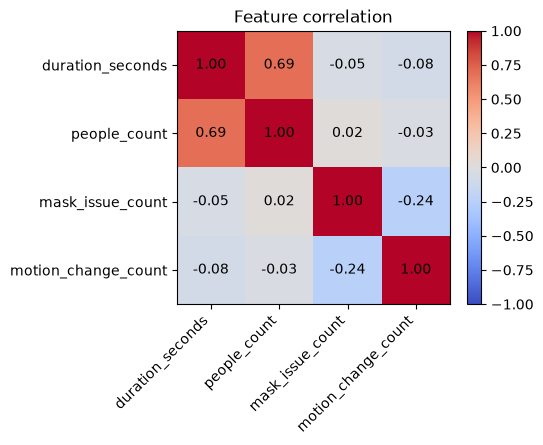

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, f in zip(axes, SAFETY_FEATURES):
    safe.boxplot(column=f, by=SAFETY_TARGET, ax=ax, rot=35)
    ax.set_title(f)
    ax.set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()

corr = safe[SAFETY_FEATURES].corr()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(SAFETY_FEATURES)))
ax.set_xticklabels(SAFETY_FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(SAFETY_FEATURES)))
ax.set_yticklabels(SAFETY_FEATURES)
for i in range(len(SAFETY_FEATURES)):
    for j in range(len(SAFETY_FEATURES)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im)
plt.title("Feature correlation")
plt.tight_layout()
plt.show()